# **Adult Data**

### import necessary libraries

In [18]:
# Data Handling
import pandas as pd
import numpy as np

# Data Preprocessing
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder , LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn import svm
from sklearn.svm import SVC
from scipy.cluster.hierarchy import fcluster

# Models
from sklearn.cluster import KMeans
from sklearn import svm

# Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay,
    silhouette_score
)

# Visualization
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.decomposition import PCA


### Load the dataset

In [19]:
# Define column names for the Adult dataset
adult_columns = [ "age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
                 "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
                 "hours-per-week", "native-country", "income" ]

In [20]:
# red the data and assign column names
adult = pd.read_csv(
    "/content/sample_data/adult.data",
    header=None,
    names=adult_columns,
    sep=",",
    na_values=" ?",
    skipinitialspace=True
)


In [21]:
# Print the first 5 rows
adult.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### Step 1: Data Preprocessing
### handling missing values

In [22]:
# Check for missing (null) values in each column of the dataset
print(adult.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


The data appeared to have no missing values, but the data source indicated that some values are missing.

This means the values are not null, but they are incomplete or invalid.

In [23]:
# Check the unique values
for col in ['workclass', 'occupation', 'native-country']:
    print(f"{col} unique values:\n{adult[col].unique()}\n")

workclass unique values:
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov' '?'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

occupation unique values:
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' '?'
 'Protective-serv' 'Armed-Forces' 'Priv-house-serv']

native-country unique values:
['United-States' 'Cuba' 'Jamaica' 'India' '?' 'Mexico' 'South'
 'Puerto-Rico' 'Honduras' 'England' 'Canada' 'Germany' 'Iran'
 'Philippines' 'Italy' 'Poland' 'Columbia' 'Cambodia' 'Thailand' 'Ecuador'
 'Laos' 'Taiwan' 'Haiti' 'Portugal' 'Dominican-Republic' 'El-Salvador'
 'France' 'Guatemala' 'China' 'Japan' 'Yugoslavia' 'Peru'
 'Outlying-US(Guam-USVI-etc)' 'Scotland' 'Trinadad&Tobago' 'Greece'
 'Nicaragua' 'Vietnam' 'Hong' 'Ireland' 'Hungary' 'Holand-Netherlands']



**Some entries in the dataset use ? to represent missing or unknown values.**

In [24]:
# Replace '?' in selected categorical columns with the mode of each column
cols_to_fix = ['workclass', 'occupation', 'native-country']
replace_dict = {col: adult[col].mode()[0] for col in cols_to_fix}
adult[cols_to_fix] = adult[cols_to_fix].replace('?', replace_dict)

In [25]:
# Check again the unique values
for col in ['workclass', 'occupation', 'native-country']:
    print(f"{col} unique values:\n{adult[col].unique()}\n")


workclass unique values:
['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

occupation unique values:
['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' 'Protective-serv'
 'Armed-Forces' 'Priv-house-serv']

native-country unique values:
['United-States' 'Cuba' 'Jamaica' 'India' 'Mexico' 'South' 'Puerto-Rico'
 'Honduras' 'England' 'Canada' 'Germany' 'Iran' 'Philippines' 'Italy'
 'Poland' 'Columbia' 'Cambodia' 'Thailand' 'Ecuador' 'Laos' 'Taiwan'
 'Haiti' 'Portugal' 'Dominican-Republic' 'El-Salvador' 'France'
 'Guatemala' 'China' 'Japan' 'Yugoslavia' 'Peru'
 'Outlying-US(Guam-USVI-etc)' 'Scotland' 'Trinadad&Tobago' 'Greece'
 'Nicaragua' 'Vietnam' 'Hong' 'Ireland' 'Hungary' 'Holand-Netherlands']



 **All '?' values have been replaced, no missing entries remain**

### Data Encoding

In [26]:
# Encode 'sex' column (binary)
le = LabelEncoder()
adult['sex'] = le.fit_transform(adult['sex'])

# One-Hot encode other categorical columns
categorical_cols = ['workclass', 'education', 'marital-status', 'occupation',
                    'relationship', 'race', 'native-country']
Eadult = pd.get_dummies(adult, columns=categorical_cols, dtype=int)

In [27]:
# Show the first 5 rows
Eadult.head()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week,income,workclass_Federal-gov,workclass_Local-gov,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,1,2174,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,83311,13,1,0,0,13,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
2,38,215646,9,1,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,234721,7,1,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,338409,13,0,0,0,40,<=50K,0,0,...,0,0,0,0,0,0,0,0,0,0


### Standardization

In [28]:
# Show statistical summary
adult.describe()

,age,fnlwgt,education-num,sex,capital-gain,capital-loss,hours-per-week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,0.669205,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,0.470506,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,1.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,1.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,1.000000,99999.000000,4356.000000,99.000000


#### The summary statistics show that the features in the dataset have very different ranges.
#### For example,
 capital-gain has a mean of 1077 and a very large standard deviation of 7385,
 while age has a mean of 38 and a standard deviation of 13. Also,
 fnlwgt reaches very large values compared to other features.

#### These variations indicate that the dataset contains features on completely different scales, which makes standardization necessary before training models like SVM and clustering, since they rely on distance-based calculations.

### Splitting Features and Target

In [29]:
X_adult = Eadult.drop("income", axis=1) # Drop target column to keep only features

Y_adult = Eadult["income"].map({'<=50K': 0, '>50K': 1})  # Convert income labels to 0 (<=50K) and 1 (>50K)

I split the data into training and testing sets before standardization to avoid data leakage. This way, the StandardScaler learns only from the training data and is not influenced by the test data, making the evaluation more accurate and realistic.
### Train-Test Data Splitting

In [30]:
# Split data into 70% training and 30% testing sets
X_train, X_test, Y_train, Y_test = train_test_split(
    X_adult, Y_adult, test_size=0.3, random_state=42, stratify=Y_adult
)


In [31]:
# Create a scaler for feature standardization (mean=0, std=1)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 2: Model Building
#### part A - Supervised Model: SVM

### SVM Classifier with Linear Kernel

In [32]:
# Create the linear SVM classifier
clf_linear_adult = svm.SVC(kernel='linear')

# Train the model on the scaled training data
clf_linear_adult.fit(X_train_scaled, Y_train)

# Predict on the scaled test data
y_pred_linear_adult = clf_linear_adult.predict(X_test_scaled)


### SVM Classifier with RBF (Non-Linear) Kernel

In [33]:
# RBF SVM Classifier
clf_rbf_adult = SVC(kernel='rbf')

# Train the model
clf_rbf_adult.fit(X_train_scaled, Y_train)

# Predict on test data
y_pred_rbf_adult = clf_rbf_adult.predict(X_test_scaled)


### Hyperparameter Tuning for Linear SVM


In [34]:
# Trying different C values for the linear SVM
clf_linear_c1 = SVC(kernel='linear', C=1)
clf_linear_c1.fit(X_train_scaled, Y_train)

clf_linear_c5 = SVC(kernel='linear', C=5)
clf_linear_c5.fit(X_train_scaled, Y_train)

clf_linear_c10 = SVC(kernel='linear', C=10)
clf_linear_c10.fit(X_train_scaled, Y_train)

# Checking test accuracy for each model
print("C=1  accuracy:", clf_linear_c1.score(X_test_scaled, Y_test))
print("C=5  accuracy:", clf_linear_c5.score(X_test_scaled, Y_test))
print("C=10 accuracy:", clf_linear_c10.score(X_test_scaled, Y_test))


C=1  accuracy: 0.8464530658204524
C=5  accuracy: 0.8463507011976661
C=10 accuracy: 0.8462483365748797



The accuracy values for C = 1, 5, and 10 were almost the same.
This means the linear SVM is not very sensitive to the C parameter.

C = 1 gave the best result.

## **Hyperparameter Tuning for RBF SVM**

In [35]:
# Trying different C and gamma values for RBF SVM
clf_rbf_1 = SVC(kernel='rbf', C=1, gamma=0.01)
clf_rbf_1.fit(X_train_scaled, Y_train)

clf_rbf_2 = SVC(kernel='rbf', C=5, gamma=0.01)
clf_rbf_2.fit(X_train_scaled, Y_train)

clf_rbf_3 = SVC(kernel='rbf', C=10, gamma=0.001)
clf_rbf_3.fit(X_train_scaled, Y_train)

# Print accuracy for each model
print("Model 1 (C=1, gamma=0.01):", clf_rbf_1.score(X_test_scaled, Y_test))
print("Model 2 (C=5, gamma=0.01):", clf_rbf_2.score(X_test_scaled, Y_test))
print("Model 3 (C=10, gamma=0.001):", clf_rbf_3.score(X_test_scaled, Y_test))


Model 1 (C=1, gamma=0.01): 0.8526973078104207
Model 2 (C=5, gamma=0.01): 0.8488074521445389
Model 3 (C=10, gamma=0.001): 0.8497287337496161



The best accuracy was achieved with C = 1 and gamma = 0.01 ,
The other parameter combinations gave slightly lower accuracy.

**Kernel & Hyperparameter Justification**


I used Linear SVM as a simple baseline to check how a linear boundary performs on this dataset.
Since the data is not perfectly linearly separable and contains mixed feature types, I also used the RBF kernel, which can capture more complex non-linear patterns.

**Hyperparameter Tuning**

For the Linear SVM, I tested different C values to adjust the margin (large C = small margin, small C = larger margin).
For the RBF kernel, I tried different C and gamma values, where gamma controls how far each point influences the decision boundary.
The best performance for this dataset was achieved with C = 1 and gamma = 0.01.

### **Part B – Unsupervised Models: K-Means & Hierarchical Clustering**

#### I scaled the full feature set because clustering uses all samples without splitting them into training and testing sets.

In [36]:
# Scale ALL adult features (without labels)
scaler = StandardScaler()
X_adult_scaled = scaler.fit_transform(X_adult)

### **K-Means Clustering**

In [37]:
# Create K-Means model with K = 2 clusters
kmeans_adult = KMeans(n_clusters=2, random_state=42)

# Fit the model on the scaled Adult dataset
kmeans_adult.fit(X_adult_scaled)

# Get cluster labels
kmeans_labels_adult = kmeans_adult.labels_

### **Hierarchical Clustering**

In [38]:
# Complete linkage clustering
complete_clustering_adult = linkage(X_adult_scaled, method="complete", metric="euclidean")

# Single linkage clustering
single_clustering_adult = linkage(X_adult_scaled, method="single", metric="euclidean")

# Labels from complete linkage
labels_complete_adult = fcluster(complete_clustering_adult, t=2, criterion='maxclust')

# Labels from single linkage
labels_single_adult = fcluster(single_clustering_adult, t=2, criterion='maxclust')

## **Step 3: Model Evaluation and Visualization**
#### **A. SVM Evaluation (Supervised)**

### **Predict class labels**

I predicted the class labels on the test set using both the linear and RBF SVM models.

In [39]:
# Predict using Linear SVM
y_pred_linear_adult = clf_linear_adult.predict(X_test_scaled)

# Predict using RBF SVM
y_pred_rbf_adult = clf_rbf_adult.predict(X_test_scaled)

## **Model evaluation**

In [40]:
# Metrics for Linear SVM
acc_linear_adult  = accuracy_score(Y_test, y_pred_linear_adult)
prec_linear_adult = precision_score(Y_test, y_pred_linear_adult)
rec_linear_adult  = recall_score(Y_test, y_pred_linear_adult)
f1_linear_adult   = f1_score(Y_test, y_pred_linear_adult)

# Decision function for ROC-AUC
scores_linear_adult = clf_linear_adult.decision_function(X_test_scaled)
roc_auc_linear_adult = roc_auc_score(Y_test, scores_linear_adult)

print("Linear SVM:")
print("Accuracy :", acc_linear_adult)
print("Precision:", prec_linear_adult)
print("Recall   :", rec_linear_adult)
print("F1-score :", f1_linear_adult)
print("ROC-AUC  :", roc_auc_linear_adult)



# Metrics for RBF SVM
acc_rbf_adult  = accuracy_score(Y_test, y_pred_rbf_adult)
prec_rbf_adult = precision_score(Y_test, y_pred_rbf_adult)
rec_rbf_adult  = recall_score(Y_test, y_pred_rbf_adult)
f1_rbf_adult   = f1_score(Y_test, y_pred_rbf_adult)

# Decision function for ROC-AUC
scores_rbf_adult = clf_rbf_adult.decision_function(X_test_scaled)
roc_auc_rbf_adult = roc_auc_score(Y_test, scores_rbf_adult)

print("\nRBF SVM:")
print("Accuracy :", acc_rbf_adult)
print("Precision:", prec_rbf_adult)
print("Recall   :", rec_rbf_adult)
print("F1-score :", f1_rbf_adult)
print("ROC-AUC  :", roc_auc_rbf_adult)


Linear SVM:
Accuracy : 0.8464530658204524
Precision: 0.7361419068736141
Recall   : 0.564625850340136
F1-score : 0.6390760346487007
ROC-AUC  : 0.8999395463996573

RBF SVM:
Accuracy : 0.8522878493192753
Precision: 0.7471451876019576
Recall   : 0.5841836734693877
F1-score : 0.6556907659269864
ROC-AUC  : 0.8959878780958251


The RBF SVM performed slightly better than the Linear SVM.
It achieved higher accuracy and F1-score, which means that a non-linear decision boundary fits this dataset better than a linear one.
However, the ROC-AUC values were close for both models.

## **ROC Curve**

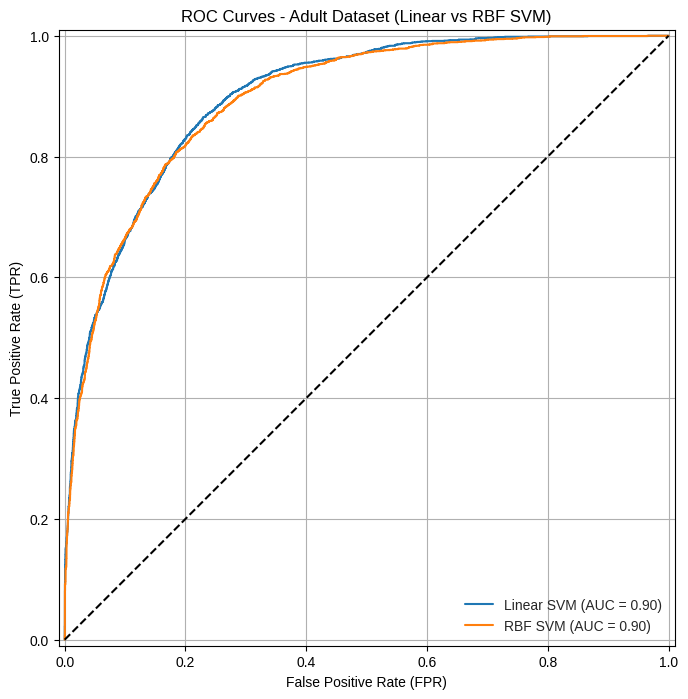

In [41]:
# Create figure
fig, ax = plt.subplots(figsize=(10, 8))
plt.style.use('seaborn-v0_8-whitegrid')

# ROC for Linear SVM
RocCurveDisplay.from_estimator(
    clf_linear_adult,
    X_test_scaled,
    Y_test,
    name="Linear SVM",
    ax=ax
)

# ROC for RBF SVM
RocCurveDisplay.from_estimator(
    clf_rbf_adult,
    X_test_scaled,
    Y_test,
    name="RBF SVM",
    ax=ax
)

# Diagonal line
plt.plot([0, 1], [0, 1], 'k--')

# Titles and labels
plt.title("ROC Curves - Adult Dataset (Linear vs RBF SVM)")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True)

plt.show()


The ROC curves for both models are almost identical, with both achieving an AUC of about 0.90. This shows that the two models have very similar ability to distinguish between the classes.

## **Confusion Matrices**

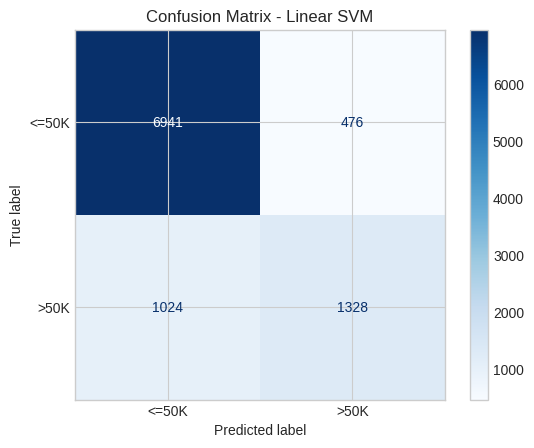

In [53]:
# Confusion matrix for Linear SVM
cm_linear_adult = confusion_matrix(Y_test, y_pred_linear_adult)

# Display confusion matrix
disp_linear_adult = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear_adult,
    display_labels=["<=50K", ">50K"]
)

disp_linear_adult.plot(cmap="Blues")
plt.title("Confusion Matrix - Linear SVM")
plt.show()


The confusion matrix shows that the model correctly predicted most samples with income ≤50K, but misclassified a noticeable number of samples with income ≥50K as ≤50K.

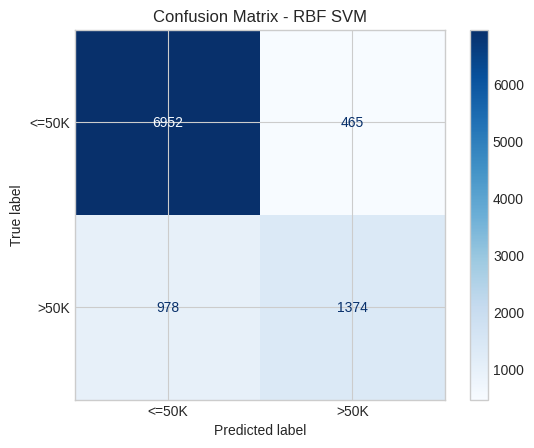

In [52]:
# Confusion matrix for RBF SVM
cm_rbf_adult = confusion_matrix(Y_test, y_pred_rbf_adult)

# Display confusion matrix
disp_rbf_adult = ConfusionMatrixDisplay(
    confusion_matrix=cm_rbf_adult,
    display_labels=["<=50K", ">50K"]
)

disp_rbf_adult.plot(cmap="Blues")
plt.title("Confusion Matrix - RBF SVM")
plt.show()


The confusion matrix shows that the model classified most samples with income ≤50K correctly, and performed slightly better than the linear model in identifying samples with income ≥50K.

The Linear SVM performed well overall and correctly predicted most samples, but it missed a noticeable number of ≥50K cases.
The RBF SVM performed slightly better, with fewer mistakes and improved detection of ≥50K samples.
Overall, the RBF model provided more reliable predictions and a clearer separation between the two classes.

## **B. Clustering Evaluation (Unsupervised)**

 **Evaluating Clustering Using Silhouette Score**

In [44]:
# Silhouette score for K-Means
sil_kmeans_adult = silhouette_score(X_adult_scaled, kmeans_labels_adult)

# Silhouette score for Hierarchical (complete linkage)
labels_complete_adult = fcluster(complete_clustering_adult, t=2, criterion='maxclust')
sil_hc_complete_adult = silhouette_score(X_adult_scaled, labels_complete_adult)

# Silhouette score for Hierarchical (single linkage)
labels_single_adult = fcluster(single_clustering_adult, t=2, criterion='maxclust')
sil_hc_single_adult = silhouette_score(X_adult_scaled, labels_single_adult)

print("Silhouette Score - KMeans:", sil_kmeans_adult)
print("Silhouette Score - HC (complete):", sil_hc_complete_adult)
print("Silhouette Score - HC (single):", sil_hc_single_adult)


Silhouette Score - KMeans: 0.058714951049135475
Silhouette Score - HC (complete): 0.9307286383739864
Silhouette Score - HC (single): 0.9307286383739864


K-Means produced a very low Silhouette score, which means it did not separate the data well.
Both complete and single linkage hierarchical clustering achieved very high Silhouette scores (≈0.93), showing that hierarchical clustering created much clearer and more separated clusters for this dataset.

## **Comparing Clusters with True Labels**





In [45]:
# Replace numeric labels (0,1) with their class names
Y_adult_named = Y_adult.replace({0: "<=50K", 1: ">50K"})

# Create crosstab
kmeans_table_adult = pd.crosstab(kmeans_labels_adult, Y_adult_named)

print("K-Means Clusters vs True Labels:\n")
print(kmeans_table_adult)

K-Means Clusters vs True Labels:

income  <=50K  >50K
row_0              
0        8160  6687
1       16560  1154


Cluster 1 contains mostly “≤50K” samples, while Cluster 0 contains a mix of both income groups.
The separation is weak because both clusters include many samples from both classes.



In [46]:
# Replace numeric income labels with class names
Y_adult_named = Y_adult.replace({0: "<=50K", 1: ">50K"})

# Create crosstab for complete linkage clustering
hc_complete_table_adult = pd.crosstab(labels_complete_adult, Y_adult_named)

print("\nHierarchical (Complete) Clusters vs True Labels:\n")
print(hc_complete_table_adult)


Hierarchical (Complete) Clusters vs True Labels:

income  <=50K  >50K
row_0              
1       24719  7841
2           1     0


Most of the samples ended up in one cluster, which shows that the data did not split into two meaningful groups.

In [47]:
# Replace numeric income labels with class names
Y_adult_named = Y_adult.replace({0: "<=50K", 1: ">50K"})

# Create crosstab for single linkage clustering
hc_single_table_adult = pd.crosstab(labels_single_adult, Y_adult_named)

print("\nHierarchical (Single) Clusters vs True Labels:\n")
print(hc_single_table_adult)


Hierarchical (Single) Clusters vs True Labels:

income  <=50K  >50K
row_0              
1       24719  7841
2           1     0


Most of the samples ended up in one cluster, while the second cluster contains only one point.
This means the data did not split into two meaningful or balanced groups.

## **PCA 2D Visualization of True Labels and Clusters**

In [48]:
# Apply PCA to reduce features to 2D
pca_adult = PCA(n_components=2)
X_adult_pca = pca_adult.fit_transform(X_adult_scaled)

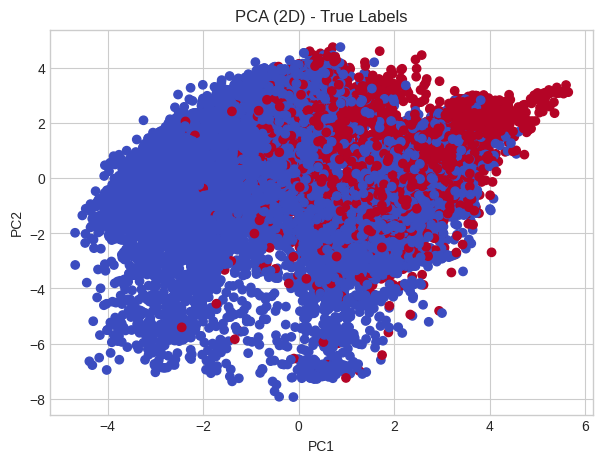

In [49]:
plt.figure(figsize=(7, 5))
plt.scatter(X_adult_pca[:, 0], X_adult_pca[:, 1], c=Y_adult, cmap='coolwarm')
plt.title("PCA (2D) - True Labels")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

The PCA plot shows a strong overlap between the two classes, meaning the data is not easily separable in two dimensions.

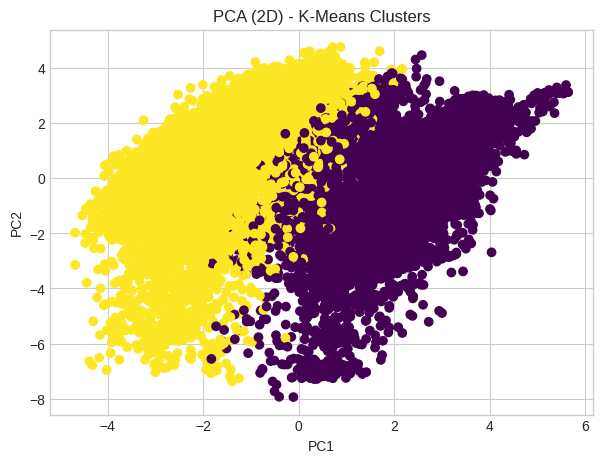

In [50]:
plt.figure(figsize=(7, 5))
plt.scatter(X_adult_pca[:, 0], X_adult_pca[:, 1], c=kmeans_labels_adult, cmap='viridis')
plt.title("PCA (2D) - K-Means Clusters")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

The two K-Means clusters are mixed ,
There is no clear separation between them, and many points from both clusters overlap.

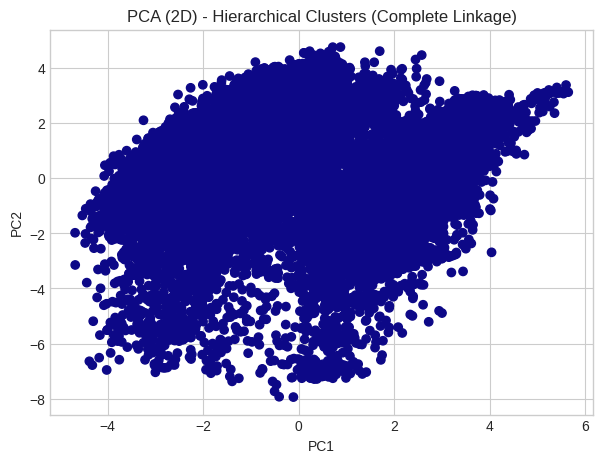

In [54]:
plt.figure(figsize=(7, 5))
plt.scatter(X_adult_pca[:, 0], X_adult_pca[:, 1], c=labels_complete_adult, cmap='plasma')
plt.title("PCA (2D) - Hierarchical Clusters (Complete Linkage)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

All the points have the same color in this plot.
This means almost all samples were placed in one cluster, and there is no real separation between groups.

## **Step 4: Comparative Analysis**

### **1. How does SVM performance compare to K-Means and Hierarchical on each dataset?**

The SVM models performed clearly better than both clustering methods.
Both Linear and RBF SVM achieved good accuracy, precision, and F1-scores, while K-Means showed very weak separation with a very low silhouette score.
Hierarchical clustering performed better than K-Means based on the silhouette score, but it still did not match the true income labels well.
Since SVM uses the real labels during training, it gave much more reliable and accurate results.


### **2. Which method seems to separate the classes better, and why?**

SVM but especially the RBF SVM separated the classes better.
It learned the actual income boundary and handled the non-linear patterns effectively.

The clustering methods struggled, because the data is complex and overlapping, which was clear from the PCA plots and contingency tables.
### **3. How did preprocessing (encoding, scaling) help your models?**

Encoding converted categorical features into numeric form so that SVM and clustering algorithms could use them.

Scaling was especially important because both SVM and clustering depend on distances.

Without scaling, large-range features (like fnlwgt or capital-gain) would dominate and harm the model.

After scaling, performance became more stable and accurate.


### **4. For each dataset, which method (SVM, K-Means, Hierarchical) would you recommend, and why?**

SVM is the best choice for this dataset,
It gives the most accurate and consistent results and can handle the complexity and overlap in the features.